# AcademiQ - Notebook 06: Feature Selection and PCA

This notebook performs two analytical workflows:
1. **Supervised Feature Selection** using `SelectKBest` with the univariate $F$-regression score.
2. **Unsupervised Dimensionality Reduction** using Principal Component Analysis (PCA) retaining 95% cumulative explained variance.


In [1]:
import os
from pathlib import Path

def get_project_root():
    current = Path.cwd().resolve()
    for candidate in [current, current.parent, current.parent.parent]:
        if (candidate / "data" / "raw").exists() or (candidate / "requirements.txt").exists():
            return candidate
    return current

PROJECT_ROOT = get_project_root()
os.chdir(PROJECT_ROOT)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
import os
import zipfile

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
    files = None

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.decomposition import PCA

print("Libraries imported successfully.")


Libraries imported successfully.


In [2]:
import os
from pathlib import Path
import pandas as pd

processed_dir = PROJECT_ROOT / "data" / "processed"
train_file = processed_dir / "AcademiQ_Train_Cleaned.csv"
test_file = processed_dir / "AcademiQ_Test_Cleaned.csv"

if not train_file.exists() and os.path.exists("/content/AcademiQ_Train_Cleaned.csv"):
    train_file = Path("/content/AcademiQ_Train_Cleaned.csv")
    test_file = Path("/content/AcademiQ_Test_Cleaned.csv")

train_df = pd.read_csv(train_file)
test_df = pd.read_csv(test_file)

target = "Exam_Score"
X_train = train_df.drop(columns=[target]).reset_index(drop=True)
X_test = test_df.drop(columns=[target]).reset_index(drop=True)
y_train = train_df[target].reset_index(drop=True)
y_test = test_df[target].reset_index(drop=True)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
display(train_df.head())


Training shape: (5285, 19)
Testing shape: (1322, 19)


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,27,79,Low,High,Yes,8,63,High,Yes,2,Low,Medium,Public,Negative,5,No,College,Moderate,Female,69
1,16,86,High,Medium,Yes,7,94,Medium,Yes,2,Low,High,Public,Neutral,3,No,High School,Moderate,Female,69
2,22,87,Low,Medium,No,8,83,Low,Yes,1,Low,Medium,Public,Neutral,1,No,College,Far,Male,66
3,18,100,High,Medium,Yes,10,86,Medium,Yes,1,Medium,Medium,Public,Neutral,3,No,High School,Near,Male,72
4,35,78,High,Low,Yes,10,99,Medium,Yes,1,Low,Medium,Private,Positive,2,No,High School,Near,Male,72


In [3]:
numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

Numerical features: ['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity']
Categorical features: ['Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Motivation_Level', 'Internet_Access', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender']


C:\Users\mansi\AppData\Local\Temp\ipykernel_26768\2989966197.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


In [4]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ],
    sparse_threshold=0.0
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (5285, 43)
Processed testing shape: (1322, 43)


In [5]:
k = min(10, X_train_processed.shape[1])

selector = SelectKBest(
    score_func=f_regression,
    k=k
)

X_train_selected = selector.fit_transform(
    X_train_processed,
    y_train
)

X_test_selected = selector.transform(
    X_test_processed
)

selected_features = feature_names[
    selector.get_support()
]

print("Selected features:")
print(selected_features)

print("\nSelected training shape:", X_train_selected.shape)
print("Selected testing shape:", X_test_selected.shape)

Selected features:
['num__Hours_Studied' 'num__Attendance' 'num__Previous_Scores'
 'num__Tutoring_Sessions' 'cat__Parental_Involvement_High'
 'cat__Parental_Involvement_Low' 'cat__Access_to_Resources_High'
 'cat__Access_to_Resources_Low' 'cat__Learning_Disabilities_Yes'
 'cat__Parental_Education_Level_Postgraduate']

Selected training shape: (5285, 10)
Selected testing shape: (1322, 10)


In [6]:
feature_scores = pd.DataFrame({
    "Feature": feature_names,
    "F_Score": selector.scores_,
    "P_Value": selector.pvalues_
})

feature_scores = feature_scores.sort_values(
    by="F_Score",
    ascending=False
)

display(feature_scores.head(15))

,Feature,F_Score,P_Value
1,num__Attendance,2666.475650,0.000000e+00
0,num__Hours_Studied,1244.444408,5.559471e-245
3,num__Previous_Scores,162.895747,9.161138e-37
4,num__Tutoring_Sessions,131.858603,3.653766e-30
9,cat__Access_to_Resources_High,119.577104,1.541910e-27
6,cat__Parental_Involvement_High,107.668401,5.514072e-25
10,cat__Access_to_Resources_Low,97.055709,1.056506e-22
7,cat__Parental_Involvement_Low,63.016824,2.484109e-15
36,cat__Parental_Education_Level_Postgraduate,54.575126,1.729773e-13
32,cat__Learning_Disabilities_Yes,44.737948,2.485304e-11


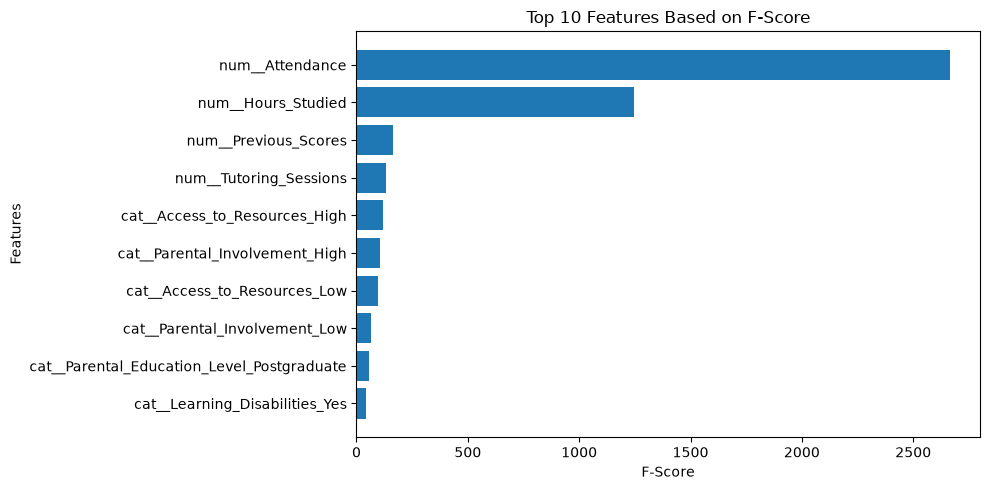

In [7]:
top_features = feature_scores.head(10)

plt.figure(figsize=(10, 5))

plt.barh(
    top_features["Feature"],
    top_features["F_Score"]
)

plt.title("Top 10 Features Based on F-Score")
plt.xlabel("F-Score")
plt.ylabel("Features")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [8]:
pca = PCA(
    n_components=0.95,
    random_state=42
)

X_train_pca = pca.fit_transform(
    X_train_processed
)

X_test_pca = pca.transform(
    X_test_processed
)

print("Original number of features:", X_train_processed.shape[1])
print("Number of PCA components:", pca.n_components_)

print("\nExplained variance:",
      round(pca.explained_variance_ratio_.sum(), 4))

Original number of features: 43
Number of PCA components: 24

Explained variance: 0.9642


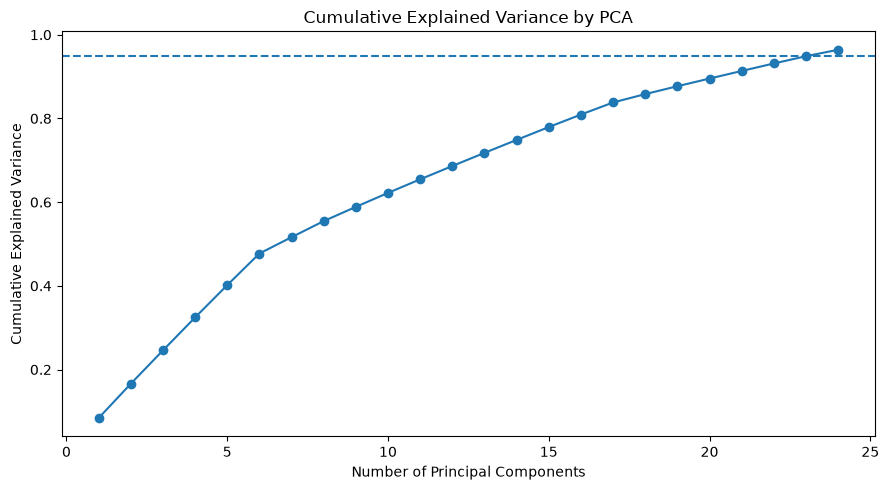

In [9]:
explained_variance = pca.explained_variance_ratio_

cumulative_variance = np.cumsum(
    explained_variance
)

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)

plt.axhline(
    y=0.95,
    linestyle="--"
)

plt.title("Cumulative Explained Variance by PCA")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.tight_layout()
plt.show()

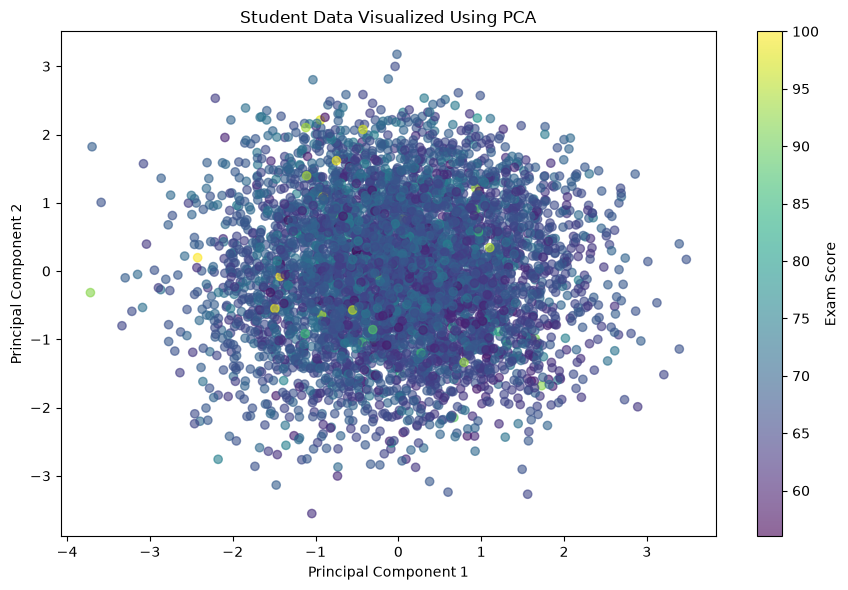

In [10]:
plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X_train_pca[:, 0],
    X_train_pca[:, 1],
    c=y_train,
    cmap="viridis",
    alpha=0.6
)

plt.colorbar(
    scatter,
    label="Exam Score"
)

plt.title("Student Data Visualized Using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.tight_layout()
plt.show()

In [11]:
results_pca_dir = PROJECT_ROOT / "results" / "feature_analysis"
results_pca_dir.mkdir(parents=True, exist_ok=True)

feature_scores.to_csv(results_pca_dir / "AcademiQ_Feature_Selection_Results.csv", index=False)
sel_df = pd.DataFrame({"Selected_Feature": selected_features})
sel_df.to_csv(results_pca_dir / "AcademiQ_Selected_Features.csv", index=False)

print("Feature selection results saved to results/feature_analysis/.")


Feature selection results saved to results/feature_analysis/.


In [12]:
processed_dir = PROJECT_ROOT / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

pca_columns = [
    f"PC{i+1}"
    for i in range(pca.n_components_)
]

train_pca_df = pd.DataFrame(
    X_train_pca,
    columns=pca_columns
)

test_pca_df = pd.DataFrame(
    X_test_pca,
    columns=pca_columns
)

train_pca_df[target] = y_train.reset_index(drop=True)
test_pca_df[target] = y_test.reset_index(drop=True)

train_pca_df.to_csv(processed_dir / "AcademiQ_Train_PCA.csv", index=False)
test_pca_df.to_csv(processed_dir / "AcademiQ_Test_PCA.csv", index=False)

print("PCA datasets saved successfully to data/processed/.")


PCA datasets saved successfully to data/processed/.


In [13]:
models_dir = PROJECT_ROOT / "models"
models_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(preprocessor, models_dir / "AcademiQ_PCA_Preprocessor.pkl")
joblib.dump(selector, models_dir / "AcademiQ_Feature_Selector.pkl")
joblib.dump(pca, models_dir / "AcademiQ_PCA_Model.pkl")

# Complete pipeline for maximum portability
pca_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("pca", pca)
])
joblib.dump(pca_pipeline, models_dir / "AcademiQ_PCA_Pipeline.pkl")

print("All trained artifacts saved successfully to models/.")


All trained artifacts saved successfully to models/.


In [14]:
results_pca_dir = PROJECT_ROOT / "results" / "feature_analysis"
results_pca_dir.mkdir(parents=True, exist_ok=True)

pca_summary = pd.DataFrame({
    "Metric": [
        "Original Features",
        "Retained Components",
        "Explained Variance"
    ],
    "Value": [
        X_train_processed.shape[1],
        pca.n_components_,
        pca.explained_variance_ratio_.sum()
    ]
})

display(pca_summary)
pca_summary.to_csv(results_pca_dir / "AcademiQ_PCA_Summary.csv", index=False)
print("PCA summary saved successfully to results/feature_analysis/.")


,Metric,Value
0,Original Features,43.000000
1,Retained Components,24.000000
2,Explained Variance,0.964216


PCA summary saved successfully to results/feature_analysis/.


In [15]:
print("All feature analysis & PCA outputs successfully organized in data/processed/, results/feature_analysis/, and models/.")


All feature analysis & PCA outputs successfully organized in data/processed/, results/feature_analysis/, and models/.
